In [10]:
import pandas as pd
import numpy as np
import random
import pyomo.environ as pyo
from pyomo.environ import *
from pyomo.environ import SolverFactory
import yfinance as yf
from pathlib import Path
import os
import matplotlib.pyplot as plt


In [11]:
anos = ['2025-12-31',
 '2024-12-31',
 '2023-12-31',
 '2022-12-31',
 '2021-12-31',
 '2020-12-31',
 '2019-12-31',
 '2018-12-31',
 '2017-12-31',
 '2016-12-31',
  ]
anos.sort(reverse=False)
anos

['2016-12-31',
 '2017-12-31',
 '2018-12-31',
 '2019-12-31',
 '2020-12-31',
 '2021-12-31',
 '2022-12-31',
 '2023-12-31',
 '2024-12-31',
 '2025-12-31']

## LER OS RETORNOS, SCORE e SELIC

In [17]:

# Retornos

dfs = {}
for ano in anos:
    ano_usado = ano.split('-')[0]
    nome = f'df_acumulados_{ano_usado}.csv'
    # caminho = Path('retornos_ativos_otimizacao') / nome
    dfs[ano_usado] = pd.read_csv('../plotagens/'+nome)
    dfs[ano_usado]['date'] = pd.to_datetime(dfs[ano_usado]['date'])
    dfs[ano_usado] = dfs[ano_usado].set_index('date')
    # dfs[ano_usado] = dfs[ano_usado].drop(columns=dfs[ano_usado].columns[(dfs[ano_usado] == 0).all()])
    
    # ativos_manter = (dfs[ano_usado]==0.0).mean()
    # c_manter = ativos_manter[ativos_manter<0.5].index
    # dfs[ano_usado] = dfs[ano_usado][c_manter]
    print(ano,'-',len(dfs[ano_usado].columns))
    

2016-12-31 - 70
2017-12-31 - 71
2018-12-31 - 76
2019-12-31 - 76
2020-12-31 - 80
2021-12-31 - 92
2022-12-31 - 99
2023-12-31 - 99
2024-12-31 - 99
2025-12-31 - 99


In [24]:
dfs['2016'].columns

Index(['ABEV3', 'ALOS3', 'ALPA4', 'ANIM3', 'AXIA3', 'AZZA3', 'B3SA3', 'BBAS3',
       'BBDC3', 'BBDC4', 'BBSE3', 'BEEF3', 'BRAP4', 'CMIG4', 'COGN3', 'CPFE3',
       'CPLE3', 'CSAN3', 'CSMG3', 'CSNA3', 'CVCB3', 'CYRE3', 'DIRR3', 'ECOR3',
       'EGIE3', 'EMBJ3', 'ENEV3', 'ENGI11', 'EQTL3', 'EZTC3', 'FLRY3', 'GGBR4',
       'GOAU4', 'HYPE3', 'ISAE4', 'ITSA4', 'ITUB3', 'ITUB4', 'JHSF3', 'KLBN11',
       'LREN3', 'MBRF3', 'MGLU3', 'MOTV3', 'MRVE3', 'MULT3', 'NATU3', 'PETR3',
       'PETR4', 'POMO4', 'PRIO3', 'PSSA3', 'RADL3', 'RAIL3', 'RENT3', 'SANB11',
       'SAUD3', 'SBSP3', 'SLCE3', 'SMTO3', 'SUZB3', 'TAEE11', 'TIMS3', 'TOTS3',
       'UGPA3', 'USIM5', 'VALE3', 'VIVT3', 'WEGE3', 'YDUQ3'],
      dtype='object')

In [25]:
dfs['2017'].columns

Index(['ABEV3', 'ALOS3', 'ALPA4', 'ANIM3', 'AXIA3', 'AZZA3', 'B3SA3', 'BBAS3',
       'BBDC3', 'BBDC4', 'BBSE3', 'BEEF3', 'BPAC11', 'BRAP4', 'CMIG4', 'COGN3',
       'CPFE3', 'CPLE3', 'CSAN3', 'CSMG3', 'CSNA3', 'CVCB3', 'CYRE3', 'DIRR3',
       'ECOR3', 'EGIE3', 'EMBJ3', 'ENEV3', 'ENGI11', 'EQTL3', 'EZTC3', 'FLRY3',
       'GGBR4', 'GOAU4', 'HYPE3', 'ISAE4', 'ITSA4', 'ITUB3', 'ITUB4', 'JHSF3',
       'KLBN11', 'LREN3', 'MBRF3', 'MGLU3', 'MOTV3', 'MRVE3', 'MULT3', 'PETR3',
       'PETR4', 'POMO4', 'PRIO3', 'PSSA3', 'RADL3', 'RAIL3', 'RENT3', 'SANB11',
       'SAUD3', 'SBSP3', 'SLCE3', 'SMTO3', 'SUZB3', 'TAEE11', 'TEND3', 'TIMS3',
       'TOTS3', 'UGPA3', 'USIM5', 'VALE3', 'VIVT3', 'WEGE3', 'YDUQ3'],
      dtype='object')

In [18]:
nomes_carteiras = os.listdir('../carteiras')
nomes_carteiras

['goal_programming',
 'linear_sharpe_mf',
 'linear_sharpe_piotroski',
 'min_var',
 'min_var_mf',
 'min_var_piotroski']

In [19]:


retorno_ibov = []
acumulado_ibov = 1.0
ll=[]
for an in anos:
            
    ano = an.split('-')[0]
    # if ano == '2015' or ano=='2026':
        # continue
    # ---------- IBOV

    df_ibov = pd.read_csv(f'../dados_retornos/plotagem/dados/ibov/df_ibov_{ano}.csv', index_col='Date', parse_dates=True)
    df_ibov = df_ibov['IBOV']
    ibov_acumulado = (df_ibov+1).cumprod()
    ibov_acumulado = ibov_acumulado*acumulado_ibov
    acumulado_ibov = ibov_acumulado.iloc[-1]
    
    retorno_ibov.append(ibov_acumulado)


for nc in nomes_carteiras:
    retorno_series = []
    acumulado = 1.0
    for n in os.listdir('../carteiras/'+nc):
        df_portfolios = pd.read_csv(f'../carteiras/{nc}/{n}').drop(columns='Unnamed: 0')
        for an in anos:
            
            ano = an.split('-')[0]
            if ano == '2015' or ano=='2026':
                continue
            carteira = df_portfolios[df_portfolios['ano']==int(ano)]
            ativos = carteira['ativo'].tolist()
            pesos = carteira['peso'].tolist()
            #calculo do turnover, uma lista com peso de tudo, os que não estao na carteira vira zero, 
            #pegar info ano anterior
            carteira_t_1 = df_portfolios[df_portfolios['ano']==int(ano)-1]
            ativos_t_1 = carteira_t_1['ativo'].tolist()
            pesos_t_1 = carteira_t_1['peso'].tolist()
            pesos_t   = carteira.set_index('ativo')['peso']
            pesos_t_1 = carteira_t_1.set_index('ativo')['peso']
            print("Carteira : ",nc, " Ano: ",an)
            turnover  = pesos_t.subtract(pesos_t_1, fill_value=0).abs().sum() / 2
            df = dfs[ano].copy()
            df = df[ativos]
            
            retorno_df = ((df*pesos).sum(axis=1)+1).cumprod()
            # retorno_df = ((1 + df).cumprod() * pesos).sum(axis=1)
            retorno_df = retorno_df*acumulado*(1-0.0003*turnover)
            acumulado = retorno_df.iloc[-1]
            retorno_series.append(retorno_df)
            print("------..-----------")

    ll.append(retorno_series)

    



Carteira :  goal_programming  Ano:  2016-12-31
------..-----------
Carteira :  goal_programming  Ano:  2017-12-31
------..-----------
Carteira :  goal_programming  Ano:  2018-12-31
------..-----------
Carteira :  goal_programming  Ano:  2019-12-31
------..-----------
Carteira :  goal_programming  Ano:  2020-12-31
------..-----------
Carteira :  goal_programming  Ano:  2021-12-31
------..-----------
Carteira :  goal_programming  Ano:  2022-12-31
------..-----------
Carteira :  goal_programming  Ano:  2023-12-31
------..-----------
Carteira :  goal_programming  Ano:  2024-12-31
------..-----------
Carteira :  goal_programming  Ano:  2025-12-31
------..-----------
Carteira :  linear_sharpe_mf  Ano:  2016-12-31
------..-----------
Carteira :  linear_sharpe_mf  Ano:  2017-12-31


KeyError: "['NATU3'] not in index"

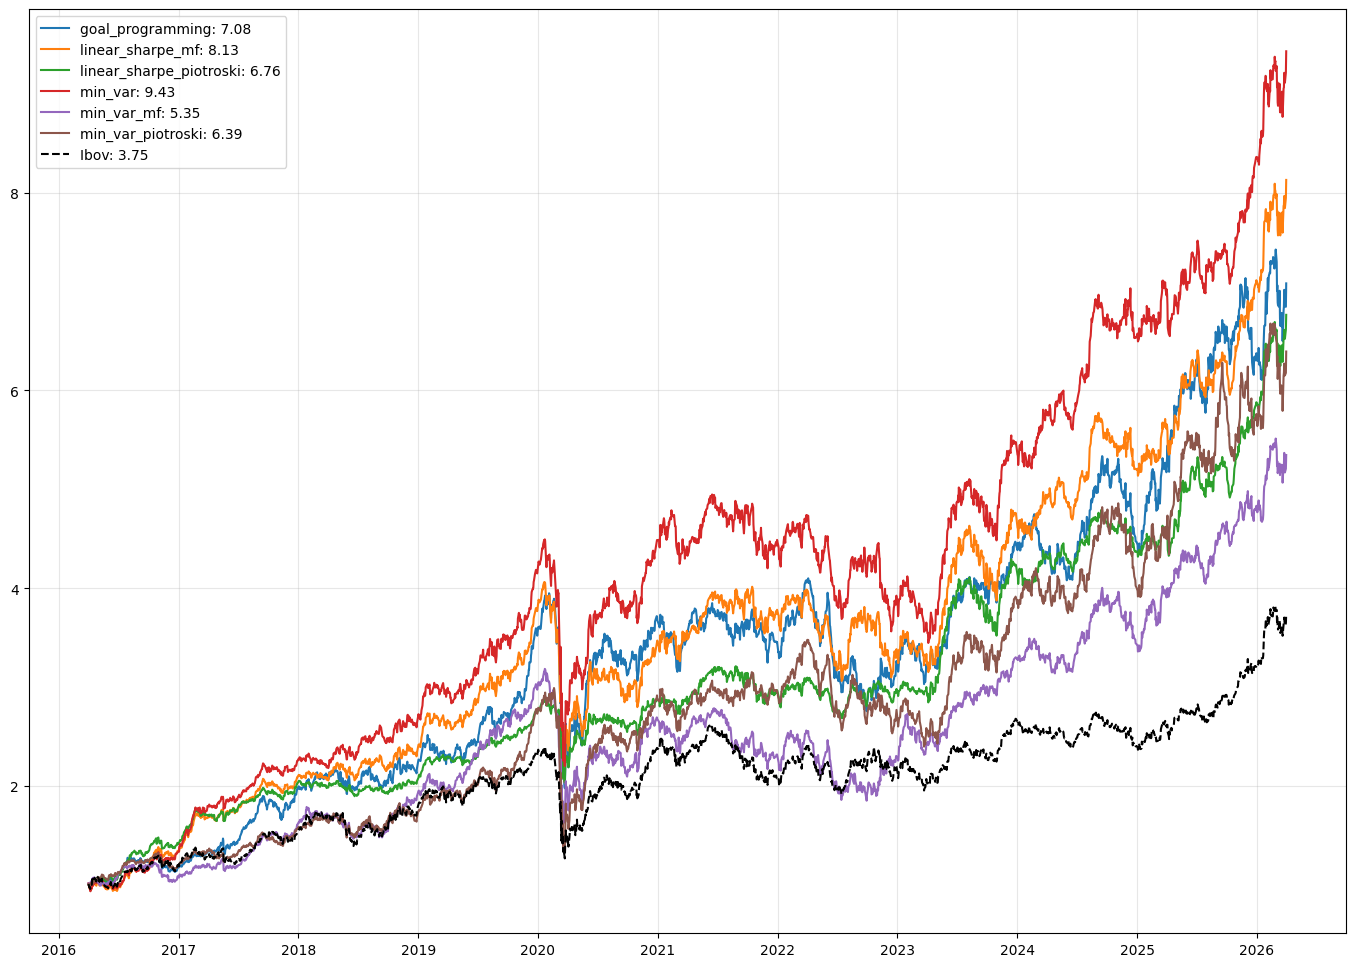

In [ ]:
plt.figure(figsize=(17,12))
for v in range(len(ll)):    
    retorno_final = pd.concat(ll[v])
    retorno_ibov_final = pd.concat(retorno_ibov)

    plt.plot(retorno_final.index, retorno_final, label=f'{nomes_carteiras[v]}: {np.round(retorno_final.iloc[-1],2)}')
    
    # print(f'{'='*18}' \
    # f'{nomes_carteiras[v]}' \
    # '' \
    # f'{'='*18}')
    # print()

    # plt.axhline(11, color='gray', linewidth=0.8)
    
plt.plot(retorno_ibov_final.index, retorno_ibov_final, label=f"Ibov: {np.round(retorno_ibov_final.iloc[-1],2)}",color='black', linestyle='--')
plt.legend()
plt.grid(alpha=0.3)
# plt.yscale('log')
plt.show()




### Tentar pegar os marcadores de cada carteira

In [ ]:
#selic
selic_d = pd.read_excel('../score-raspagem/selic/selic.xlsx')
# selic_d['Date'] = selic_d['Date'].
selic_d = selic_d.set_index('Date')
df_final = {}

lista_final = []

lista_composicao = []
for nc in nomes_carteiras:
    cart = os.listdir('../carteiras/'+nc)    
    print(cart)
    df_portfolios = pd.read_csv(f'../carteiras/{nc}/{cart[0]}').drop(columns='Unnamed: 0')
    for an in anos:
        
        ano = an.split('-')[0]
        if ano == '2015' or ano=='2026':
            continue
        carteira = df_portfolios[df_portfolios['ano']==int(ano)]
        ativos = carteira['ativo'].tolist()
        pesos = carteira['peso'].tolist()

        dc_composicao = {}


        texto = ' '.join(nc.split('_'))
        dc_composicao[texto+' '+ano] = {
            'ativos': ativos,
            'pesos':np.round(pesos,3),
            'quantidade_ativos': len(ativos),
        }
        lista_composicao.append(dc_composicao)
        df = dfs[ano].copy()
        df = df[ativos]
        retorno_df = (df*pesos).sum(axis=1)

        # SELIC
        slc = selic_d['selic'].reindex(retorno_df.index)/ 100
        excesso_retorno = retorno_df.sub(slc,axis=0)
        # print("SLC ",slc.isna().sum())
        # print("SLC ANO",(1+slc).prod()-1)

        # calculos
        retorno_medio = ((1+retorno_df).mean()-1)*100
        retorno_total_ano = ((1+retorno_df).prod()-1)*100
        porcentagem_valores_positivos = (retorno_df>0).mean()
        menor_retorno_valor = retorno_df.min()
        melhor_retorno_valor = retorno_df.max()

        # Espaço de verificações
        # Goal programminh queda de ~ -18% ... Qual dia?
        print(f"Data inicial: {retorno_df.index[0]} || Data Final: {retorno_df.index[-1]}")
        print(retorno_df.idxmin(), '-->',menor_retorno_valor)

        #riscos
        
        desvio_padrao_diario = retorno_df.std()
        # excesso_retorno = retorno_df- 0.001365
        sharpe_do_ano = (excesso_retorno.mean()/retorno_df.std())*np.sqrt(252)

        print(f"Carteira {texto} -> {ano}: \n"
              f"====== RETORNOS ============ \n"
              f"Retorno Médio Diário = {np.round(retorno_medio,2)}% \n"
              f"Retorno total do período = {np.round(retorno_total_ano,2)}% \n"
              f"% Dias Positivos {np.round(porcentagem_valores_positivos*100,2)}% \n"
              f"Pior Retorno: {np.round(menor_retorno_valor*100,2)}% & Melhor Retorno: {np.round(melhor_retorno_valor*100,2)}% \n"
              f"====== RISCO ============ \n"
              f"Sharpe: {sharpe_do_ano} \n"
              f"Desvio Padrão Diário: {np.round(desvio_padrao_diario*100,2)} %"
              )
        dados = []
        dados = [retorno_medio,retorno_total_ano,porcentagem_valores_positivos,menor_retorno_valor,melhor_retorno_valor,sharpe_do_ano,desvio_padrao_diario]
        dicio = {}
        dicio[texto+' '+ano]=dados
        f = pd.DataFrame(dicio)

        lista_final.append(f)
        

['carteiras_goal_programming.csv']
Data inicial: 2016-04-01 00:00:00 || Data Final: 2017-03-31 00:00:00
2016-12-01 00:00:00 --> -0.03548771848009967
Carteira goal programming -> 2016: 
====== RETORNOS ============ 
Retorno Médio Diário = 0.12% 
Retorno total do período = 33.71% 
% Dias Positivos 55.38% 
Pior Retorno: -3.55% & Melhor Retorno: 2.96% 
====== RISCO ============ 
Sharpe: 1.0829282685042272 
Desvio Padrão Diário: 1.03 %
Data inicial: 2017-04-03 00:00:00 || Data Final: 2018-03-29 00:00:00
2017-05-18 00:00:00 --> -0.07691682888206437
Carteira goal programming -> 2017: 
====== RETORNOS ============ 
Retorno Médio Diário = 0.19% 
Retorno total do período = 58.4% 
% Dias Positivos 59.68% 
Pior Retorno: -7.69% & Melhor Retorno: 3.32% 
====== RISCO ============ 
Sharpe: 2.0058450875039555 
Desvio Padrão Diário: 1.28 %
Data inicial: 2018-04-02 00:00:00 || Data Final: 2019-03-29 00:00:00
2018-05-28 00:00:00 --> -0.047815325830620384
Carteira goal programming -> 2018: 
====== RETORNOS

In [ ]:
nomes_marcadores = [
    'retorno_medio','retorno_total_ano','porcentagem_valores_positivos','menor_retorno_valor','melhor_retorno_valor','sharpe_do_ano','desvio_padrao_diario'
]

In [ ]:
d = pd.concat(lista_final,axis=1).set_index([nomes_marcadores])
# d.T.to_excel('indicadores.xlsx')
# d.T.to_csv('indicadores.csv')

In [ ]:
dd={}
for i in range(10):
    cart = d.columns[i::10]
    # print(cart)
    dd[i] = d[cart]



In [ ]:
dd[9].T

,retorno_medio,retorno_total_ano,porcentagem_valores_positivos,menor_retorno_valor,melhor_retorno_valor,sharpe_do_ano,desvio_padrao_diario
goal programming 2025,0.136893,36.925693,0.524,-0.056054,0.052973,0.872685,0.014943
linear sharpe mf 2025,0.153912,44.893239,0.576,-0.030942,0.035717,1.501522,0.010484
linear sharpe piotroski 2025,0.165260,48.938758,0.576,-0.028655,0.037241,1.626406,0.010787
min var 2025,0.126216,35.454608,0.576,-0.033346,0.032730,1.161516,0.009768
min var mf 2025,0.131888,36.848118,0.588,-0.033803,0.036034,1.086519,0.011271
min var piotroski 2025,0.154146,42.145421,0.516,-0.061734,0.061196,0.962113,0.016401


In [ ]:
df_composicao_final = []
for comp in lista_composicao:
    df = pd.DataFrame(comp).T
    df_composicao_final.append(df)

In [ ]:
dd_comp={}
for i in range(10):
    # print(cart)
    dd_comp[i] = df_composicao_final[i::10]


In [ ]:
pd.set_option('display.max_colwidth', None)
# print(sum(pd.concat(dd_comp[8]).iloc[8]['pesos']))
pd.concat(dd_comp[1])

,ativos,pesos,quantidade_ativos
goal programming 2017,"[CVCB3, EGIE3, ISAE4, MGLU3, MOTV3, SBSP3, VALE3]","[0.15, 0.15, 0.15, 0.15, 0.1, 0.15, 0.15]",7
linear sharpe mf 2017,"[ANIM3, AZZA3, B3SA3, BBSE3, BEEF3, CSMG3, EMBJ3, ENEV3, ENGI11, FLRY3, KLBN11, MRVE3, PRIO3, PSSA3, SAUD3, SMTO3, TAEE11, TOTS3, VIVT3]","[0.073, 0.024, 0.013, 0.007, 0.114, 0.139, 0.065, 0.112, 0.014, 0.025, 0.03, 0.018, 0.012, 0.035, 0.057, 0.007, 0.072, 0.034, 0.15]",19
linear sharpe piotroski 2017,"[ALPA4, ANIM3, AZZA3, B3SA3, BEEF3, CSMG3, EMBJ3, ENEV3, ENGI11, FLRY3, KLBN11, MRVE3, PRIO3, TAEE11, TOTS3]","[0.02, 0.076, 0.025, 0.018, 0.121, 0.144, 0.084, 0.091, 0.029, 0.027, 0.033, 0.01, 0.018, 0.08, 0.03]",15
min var 2017,"[ALOS3, ANIM3, AZZA3, BEEF3, CSMG3, CYRE3, EMBJ3, ENEV3, ENGI11, FLRY3, KLBN11, MRVE3, POMO4, PRIO3, PSSA3, SAUD3, SMTO3, TAEE11, TOTS3, VIVT3]","[0.006, 0.075, 0.01, 0.123, 0.086, 0.035, 0.0, 0.15, 0.014, 0.025, 0.043, 0.028, 0.015, 0.045, 0.055, 0.073, 0.025, 0.055, 0.033, 0.102]",20
min var mf 2017,"[ABEV3, BBDC3, BBDC4, CVCB3, ISAE4, PRIO3, SAUD3]","[0.15, 0.15, 0.15, 0.15, 0.15, 0.1, 0.15]",7
min var piotroski 2017,"[CSMG3, EGIE3, EMBJ3, ENEV3, FLRY3, HYPE3, SBSP3, VALE3, VIVT3]","[0.15, 0.15, 0.064, 0.15, 0.003, 0.033, 0.15, 0.15, 0.15]",9


In [ ]:
lista_composicao_final_final = []
for i in range(len(dd_comp)):
    didi = pd.concat(dd_comp[i])
    lista_composicao_final_final.append(didi)

pd.concat(lista_composicao_final_final).to_excel("comp_comp.xlsx")

In [ ]:
pd.concat(df_composicao_final).to_excel('compo.xlsx')